# 1. Control de calidad de datos registrados

En esta primera sección, se verifica la integridad de los datos y la consistencia de la información asociada a cada registro en los archivos `.csv`: detección de valores faltantes o no válidos (NaN, infinitos), comprobación de correspondencia entre sujetos, experimentos, condiciones de escucha y canales de adquisición, etc.

Por otro lado, se revisan los metadatos de los participantes (`Subjects.csv`) y las canciones utilizadas (`Songs.csv`) para identificar inconsistencias o ambigüedades.

## 1.0. Configuración e importaciones


In [36]:
%load_ext autoreload
%autoreload 2

# --- Subir un nivel (..) para encontrar procesamiento_eeg.py en la raíz ---
sys.path.append(os.path.abspath('..'))

# --- Imports ---
import sys
import os
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import procesamiento_eeg as eeg

# --- Ruta a la carpeta ---
ruta_datos = '../datos/Segmented_Data'



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1.1 Chequeo de valores en archivos .csv

In [12]:
# --- Llamado a función auditar_dataset_segmentado ---

df_reporte = eeg.auditar_dataset_segmentado(ruta_datos)
display(df_reporte)

--- Auditoría de calidad sobre 40 archivos ---

Resumen del Control de Calidad:
Archivos válidos: 40 / 40
Todos los archivos pasaron el control de calidad perfectamente


,archivo,sujeto,condicion,valido,observacion
0,s01_ex05.csv,s01,Nativo,True,OK
1,s01_ex06.csv,s01,No_Nativo,True,OK
2,s02_ex05.csv,s02,Nativo,True,OK
3,s02_ex06.csv,s02,No_Nativo,True,OK
4,s03_ex05.csv,s03,Nativo,True,OK
5,s03_ex06.csv,s03,No_Nativo,True,OK
6,s04_ex05.csv,s04,Nativo,True,OK
7,s04_ex06.csv,s04,No_Nativo,True,OK
8,s05_ex05.csv,s05,Nativo,True,OK
9,s05_ex06.csv,s05,No_Nativo,True,OK


## 1.2 Chequeo de metadatos de sujetos
Tras comprobar que todos los canales poseen valores válidos, se procedió a la inspección de metadatos de forma manual, evaluando la consistencia entre idioma nativo, canciones y comentarios.

In [33]:
# Ruta al archivo .csv de metadatos de sujetos
ruta_demo = '../datos/Subjects.csv'  

# 1. Cargar el CSV
df_demo = pd.read_csv(ruta_demo)

# 2. Limpiar espacios extras en nombres de columnas y textos
df_demo.columns = df_demo.columns.str.strip()
for col in df_demo.select_dtypes(include='object').columns:
    df_demo[col] = df_demo[col].astype(str).str.strip()


df_demo['Alcoholic'] = df_demo['Alcoholic'].replace('Neve', 'Never')


display(df_demo)

C:\Users\Camila\AppData\Local\Temp\ipykernel_28696\1341240978.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_demo.select_dtypes(include='object').columns:


,Subject ID,Age,Gender,Smoke,Alcoholic,Medication,Mother Language,BMI,comments
0,S01,27,Male,Yes,Occasionally,No,Italian,25.925926,NaN
1,S02,23,Female,Yes,Occasionally,No,Italian,22.948116,NaN
2,S03,26,Male,No,Occasionally,No,Arabic,20.452885,NaN
3,S04,29,Male,No,Occasionally,No,Arabic,27.459822,NaN
4,S05,28,Male,Yes,Never,No,Arabic,27.770313,NaN
5,S06,27,Male,Yes,Never,No,Arabic,28.408163,NaN
6,S07,25,Male,No,Occasionally,No,Latvian,22.038401,NaN
7,S08,24,Female,No,Usually,Yes,Italian,21.875000,NaN
8,S09,30,Female,No,Usually,No,Arabic,23.183391,NaN
9,S10,26,Male,No,Occasionally,Yes,Italian,26.061679,NaN


Obsérvese que el sujeto número 19 (18 en la tabla pues empieza en 0) tiene como lengua madre el italiano, pero el comentario indica "Fluent in Italian". Esto podría tratarse tanto de una redundancia como de un error en la anotación de su lengua materna. Ante esta ambigüedad, se decidió excluir este par de registros (s19_ex05 y s19_ex06) del estudio.

Por otro lado, los sujetos S12 y S13 comparten la totalidad de sus datos(edad, género, hábitos y valor exacto de BIM). Para descartar que se tratara de un archivo de señal duplicado bajo dos nombres distintos, se realizó una verificación de independencia temporal y correlación cruzada canal por canal entre las señales de EEG de ambos registros (s12 vs. s13 para las condiciones ex05 y ex06).Los resultados confirmaron que las señales no son idénticas y que la correlación lineal entre sus canales es prácticamente nula, lo que demuestra que corresponden a dos adquisiciones de EEG independientes. Se determinó que la duplicación responde a un error en la carga de los metadatos, conservando ambos sujetos en el estudio.

De esta manera, se tiene un total de 19 sujetos con 2 registros cada uno, es decir, 38 registros en total.

In [34]:
for ex in ['ex05', 'ex06']:
    a = pd.read_csv(os.path.join(ruta_datos, f's12_{ex}.csv'))
    b = pd.read_csv(os.path.join(ruta_datos, f's13_{ex}.csv'))
    print(f"--- {ex} ---")
    print("shape:", a.shape, b.shape)
    print("mismas columnas:", list(a.columns) == list(b.columns))

    canales = a.columns[1:]
    n = min(len(a), len(b))
    xa = a[canales].to_numpy(dtype=float)[:n]
    xb = b[canales].to_numpy(dtype=float)[:n]

    print("idénticos (exacto):", np.array_equal(xa, xb))
    print("casi idénticos (allclose):", np.allclose(xa, xb))
    for i, c in enumerate(canales):
        r = np.corrcoef(xa[:, i], xb[:, i])[0, 1]
        print(f"  {c}: correlación = {r:.4f}")

--- ex05 ---
shape: (24000, 5) (24000, 5)
mismas columnas: True
idénticos (exacto): False
casi idénticos (allclose): False
  T7: correlación = 0.0019
  F8: correlación = 0.0019
  Cz: correlación = 0.0082
  P4: correlación = 0.0036
--- ex06 ---
shape: (24000, 5) (24000, 5)
mismas columnas: True
idénticos (exacto): False
casi idénticos (allclose): False
  T7: correlación = -0.0111
  F8: correlación = -0.0134
  Cz: correlación = -0.0072
  P4: correlación = -0.0106


## 1.3 Inspección de métricas en canales

Se calcula el desvío estándar, la amplitud máxima y la cantidad de veces que la diferencia entre una muestra y la anterior es cero, para así identificar canales con artefactos, planos (que producen una señal sin variaciones), etc.

En particular, para marcar sospechosos se comparó el desvío estándar de cada canal con la mediana de su registro, fijando dos umbrales:
 - 5 veces la mediana para canales con artefactos de gran amplitud.
 - 0,1 veces la mediana para canales planos.

In [ ]:
excluidos = ['s19']
archivos_ok = [a for a in df_reporte['archivo'] if not a.startswith(excluidos)]

df_canales = eeg.screening_canales(ruta_datos, archivos_ok)
print(len(archivos_ok), "registros")
display(df_canales[df_canales['Sospechoso']])

38 registros


,Archivo,Canal,Desvío estándar,Proporción de diferencias entre muestras iguales a cero,Amplitud máxima,Sospechoso,Motivo
5,s01_ex06.csv,F8,114.523752,0.000083,1134.299631,True,Desvío estándar muy alto


Graficando el canal sospechoso...

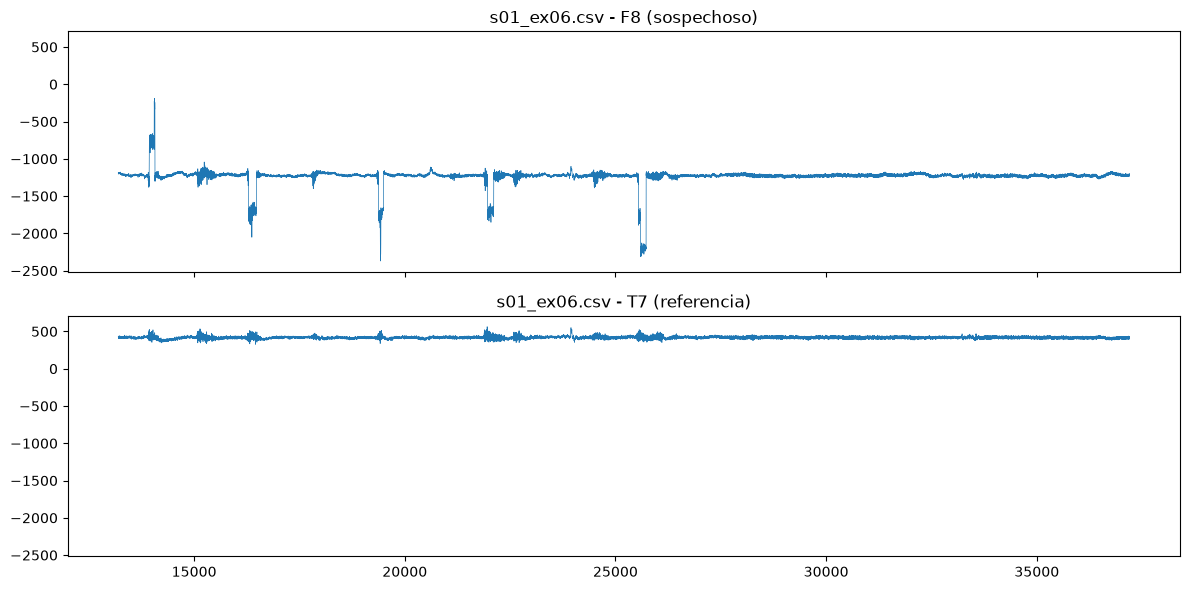

In [37]:
sospechoso = df_canales[df_canales["Sospechoso"]]
fila = sospechoso.iloc[0]
df = pd.read_csv(os.path.join(ruta_datos, fila["Archivo"]))
t= df.iloc[:,0]
canales = list(df.columns[1:])
# canal sospechoso y, de referencia, el canal con std más cercano a la mediana
stds = df[canales].std()
ref = (stds - stds.median()).abs().idxmin()

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
axs[0].plot(t, df[fila['Canal']], lw=0.5)
axs[0].set_title(f"{fila['Archivo']} - {fila['Canal']} (sospechoso)")
axs[1].plot(t, df[ref], lw=0.5)
axs[1].set_title(f"{fila['Archivo']} - {ref} (referencia)")
plt.tight_layout()
plt.show()
plt.close()

Se observa la presencia de varios picos en el registro, aparentemente debidos a artefactos puntuales. Comparando contra el canal T7, en las zonas de los picos hay ensanchamientos de la señal, por lo que es posible que coincidan con movimientos del sujeto en los primeros momentos del registro, ya que luego se estabiliza la señal para ambos.

Se optó por conservar el registro y el canal.